In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import torch
import numpy as np
import sklearn as sk
import torch.nn as nn
import seaborn as sns
import matplotlib.pyplot as plt

# DATASET

In [2]:
from datasets.datasets import load_AUTOMPG

dataset = load_AUTOMPG()

In [3]:
train_dataset = dataset.sample(frac=0.8)
test_dataset = dataset.drop(train_dataset.index)

print(f"TRAIN SET shape: {train_dataset.shape}")
print(f"TEST SET shape: {test_dataset.shape}\n")

TRAIN SET shape: (314, 6)
TEST SET shape: (78, 6)



array([[-0.87073567, -1.01107037, -0.78530384, -1.02693936, -0.38036536],
       [-0.87073567, -0.53106418, -0.44351791, -0.1189854 ,  0.62509834],
       [ 1.48625572,  1.48496183,  1.44945034,  1.73964976, -0.73945954],
       [-0.87073567, -0.86706851, -1.10079855, -1.02693936, -0.30854653],
       [-0.87073567, -0.9438695 , -0.99563364, -1.003202  ,  0.87646427],
       [ 0.30776002,  0.35214722, -0.39093545,  0.26081234,  0.58918892],
       [-0.87073567, -1.02067049, -1.17967222, -1.21327762,  1.16373961],
       [-0.87073567, -0.47346343, -0.99563364,  0.30828705,  2.24102215],
       [ 0.30776002,  0.02574301, -0.25947933,  0.1326306 ,  0.337823  ],
       [-0.87073567, -0.9438695 , -0.44351791, -0.8441617 ,  1.23555845]])

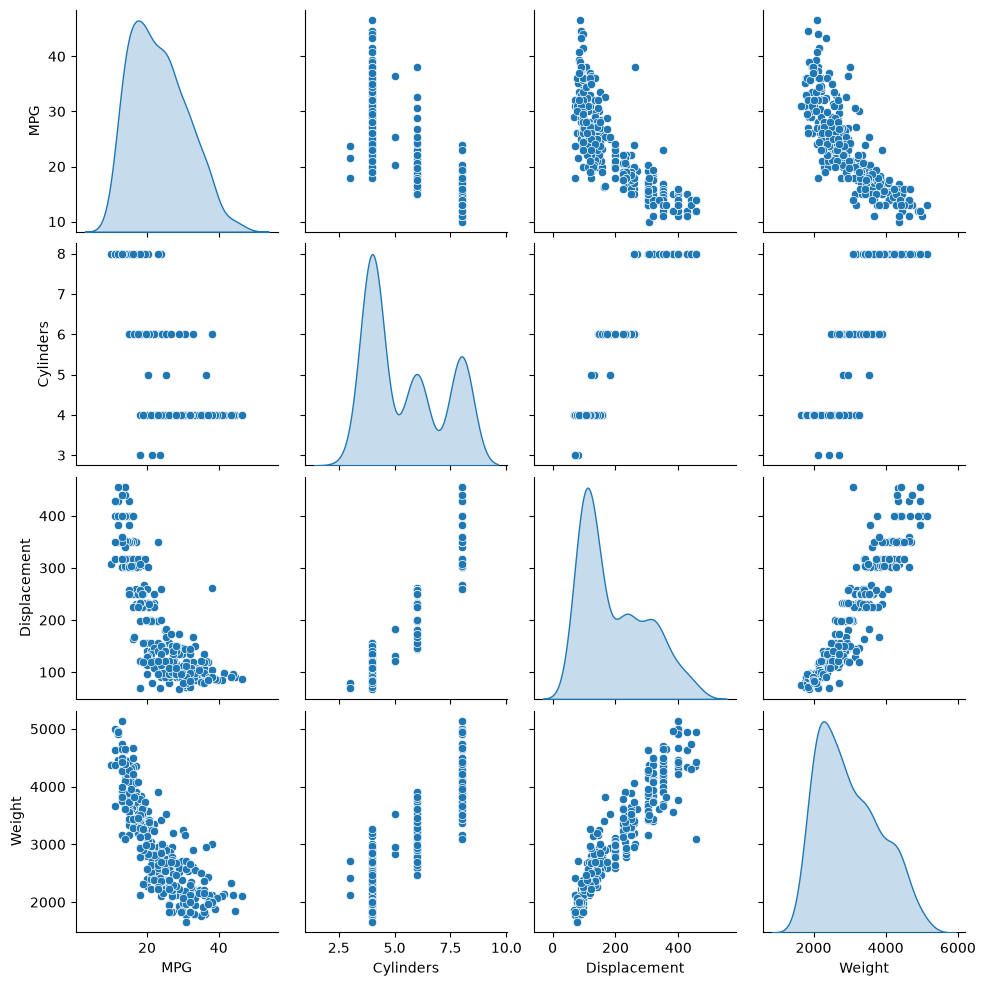

In [6]:
sns.pairplot(train_dataset[["MPG", "Cylinders", "Displacement", "Weight"]], diag_kind="kde")
train_labels = train_dataset.pop('MPG')
test_labels = test_dataset.pop('MPG')

scaler = sk.preprocessing.StandardScaler().fit(train_dataset)

normed_train_data = scaler.transform(train_dataset)
normed_test_data = scaler.transform(test_dataset)
normed_train_data[0:10]

## MODEL DEFINITION

In [7]:
model = nn.Sequential(
nn.Linear(train_dataset.shape[1], 64),
nn.ReLU(),
nn.Linear(64, 64),
nn.ReLU(),
nn.Linear(64, 1)
)

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, betas=(0.9, 0.999), eps=1e-7)

print(model)
print(f"Total params: {sum(p.numel() for p in model.parameters()):,}")

Sequential(
  (0): Linear(in_features=5, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=1, bias=True)
)
Total params: 4,609


## TRAIN

Epoch 1/250 - loss: 582.9876 - mse: 582.9876 - val_loss: 598.1874 - val_mse: 598.1874
Epoch 2/250 - loss: 565.1055 - mse: 565.1055 - val_loss: 576.5900 - val_mse: 576.5900


C:\Users\Francesco De Luca\AppData\Local\Temp\ipykernel_13368\1359176883.py:6: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  y = torch.as_tensor(train_labels.values, dtype=torch.float32).reshape(-1, 1)


Epoch 3/250 - loss: 542.5542 - mse: 542.5542 - val_loss: 547.1074 - val_mse: 547.1074
Epoch 4/250 - loss: 512.4064 - mse: 512.4064 - val_loss: 508.4918 - val_mse: 508.4918
Epoch 5/250 - loss: 472.1757 - mse: 472.1757 - val_loss: 459.8346 - val_mse: 459.8346
Epoch 6/250 - loss: 422.6035 - mse: 422.6035 - val_loss: 400.1067 - val_mse: 400.1067
Epoch 7/250 - loss: 363.8360 - mse: 363.8360 - val_loss: 331.8222 - val_mse: 331.8222
Epoch 8/250 - loss: 296.7912 - mse: 296.7912 - val_loss: 260.5381 - val_mse: 260.5381
Epoch 9/250 - loss: 229.8188 - mse: 229.8188 - val_loss: 190.9482 - val_mse: 190.9482
Epoch 10/250 - loss: 165.7258 - mse: 165.7258 - val_loss: 130.6220 - val_mse: 130.6220
Epoch 11/250 - loss: 111.8474 - mse: 111.8474 - val_loss: 85.6521 - val_mse: 85.6521
Epoch 12/250 - loss: 73.3078 - mse: 73.3078 - val_loss: 60.3239 - val_mse: 60.3239
Epoch 13/250 - loss: 53.1423 - mse: 53.1423 - val_loss: 52.0529 - val_mse: 52.0529
Epoch 14/250 - loss: 46.3575 - mse: 46.3575 - val_loss: 51.7

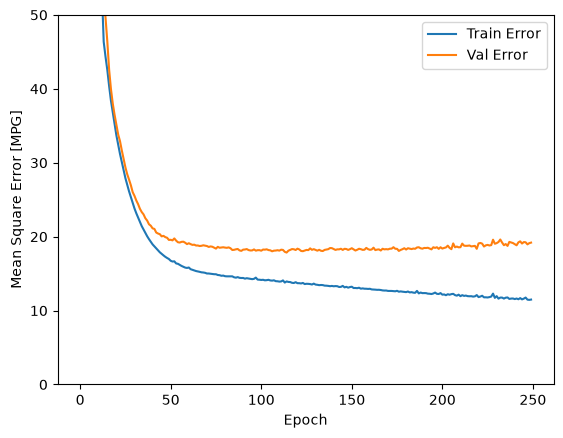

In [8]:
EPOCHS = 250
VERBOSE = 1
BATCH_SIZE = 32

x = torch.as_tensor(normed_train_data, dtype=torch.float32)
y = torch.as_tensor(train_labels.values, dtype=torch.float32).reshape(-1, 1)

split = int(len(x) * (1 - 0.2))
x_train, y_train = x[:split], y[:split]
x_val, y_val = x[split:], y[split:]

history_dict = {"loss": [], "mse": [], "val_loss": [], "val_mse": []}
n = len(x_train)
for epoch in range(EPOCHS):

    model.train()
    perm = torch.randperm(n)
    run_loss = 0.0
    for i in range(0, n, BATCH_SIZE):
        idx = perm[i:i + BATCH_SIZE]
        loss = loss_fn(model(x_train[idx]), y_train[idx])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        run_loss += loss.item() * len(idx)

    # validazione
    model.eval()
    with torch.no_grad():
        val_loss = loss_fn(model(x_val), y_val).item()

    # loss e metrica coincidono perché la loss è già la MSE
    history_dict["loss"].append(run_loss / n)
    history_dict["mse"].append(run_loss / n)
    history_dict["val_loss"].append(val_loss)
    history_dict["val_mse"].append(val_loss)
    if VERBOSE:
        print(f"Epoch {epoch + 1}/{EPOCHS} - loss: {history_dict['loss'][-1]:.4f} - mse: {history_dict['mse'][-1]:.4f}"
              f" - val_loss: {history_dict['val_loss'][-1]:.4f} - val_mse: {history_dict['val_mse'][-1]:.4f}")

e = range(EPOCHS)
plt.figure()
plt.xlabel('Epoch')
plt.ylabel('Mean Square Error [MPG]')
plt.plot(e, history_dict['mse'],label='Train Error')
plt.plot(e, history_dict['val_mse'], label = 'Val Error')
plt.ylim([0,50])
plt.legend()
plt.show()

## EVAL

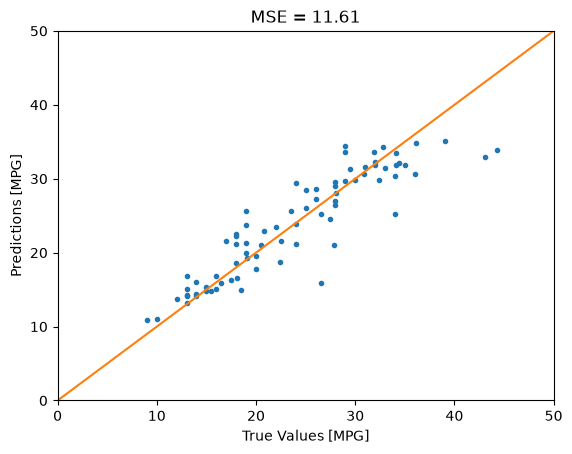

In [9]:
x_test = torch.as_tensor(normed_test_data, dtype=torch.float32)
y_test = torch.as_tensor(test_labels.values, dtype=torch.float32).reshape(-1, 1)

model.eval()
with torch.no_grad():
    test_predictions = model(x_test)
    loss = mse = loss_fn(test_predictions, y_test).item()  # equivalente di model.evaluate
test_predictions = test_predictions.numpy()                # equivalente di model.predict

plt.figure()
#a = plt.axes(aspect='equal')
plt.title(f"MSE = {'%.2f'%(mse)}")
plt.plot(np.array(test_labels), test_predictions,'.')
plt.xlabel('True Values [MPG]')
plt.ylabel('Predictions [MPG]')

lims = [0, 50]
plt.xlim(lims)
plt.ylim(lims)
plt.plot(lims, lims)
plt.show()

## MODEL

In [11]:
model = nn.Sequential(
nn.Linear(train_dataset.shape[1], 64),
nn.ReLU(),
nn.Linear(64, 64),
nn.ReLU(),
nn.Linear(64, 1)
)

class RegularizedMSELoss(nn.Module):


    def __init__(self, model, lam=1e-3):
        super().__init__()
        self.lam = lam
        self.l2_weights = [m.weight for m in model.modules() if isinstance(m, nn.Linear)]


    def forward(self, y_pred, y_true):

        l2_penalty = sum(w.pow(2).sum() for w in self.l2_weights)
        return  torch.mean((y_pred - y_true) ** 2) + self.lam * l2_penalty


class CustomMSELoss(nn.Module):

    def __init__(self, alpha):
        super(CustomMSELoss, self).__init__()
        self.alpha = alpha

    def forward(self, y_pred, y_true):
        diff = y_pred - y_true

        # Fattore di penalizzazione extra quando y_pred > y_true (diff > 0)
        # alpha = 1.0 significa penalità normale, alpha > 1 penalizza di più le sovrastime.

        # Se diff > 0, moltiplica l'errore al quadrato per alpha, altrimenti usa l'errore normale
        loss = torch.where(diff > 0, self.alpha * (diff ** 2), (diff ** 2))

        return torch.mean(loss)

loss_fn = CustomMSELoss(10)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, betas=(0.9, 0.999), eps=1e-7)

print(model)
print(f"Total params: {sum(p.numel() for p in model.parameters()):,}")

Sequential(
  (0): Linear(in_features=5, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=1, bias=True)
)
Total params: 4,609


## TRAIN

Epoch 1/250 - loss: 595.0987 - mse: 595.0987 - val_loss: 611.9714 - val_mse: 611.9714
Epoch 2/250 - loss: 579.2955 - mse: 579.2955 - val_loss: 592.7312 - val_mse: 592.7312
Epoch 3/250 - loss: 559.8285 - mse: 559.8285 - val_loss: 568.3882 - val_mse: 568.3882
Epoch 4/250 - loss: 534.4516 - mse: 534.4516 - val_loss: 536.6638 - val_mse: 536.6638
Epoch 5/250 - loss: 502.2555 - mse: 502.2555 - val_loss: 495.6170 - val_mse: 495.6170
Epoch 6/250 - loss: 459.0634 - mse: 459.0634 - val_loss: 445.1302 - val_mse: 445.1302
Epoch 7/250 - loss: 409.6523 - mse: 409.6523 - val_loss: 384.2935 - val_mse: 384.2935
Epoch 8/250 - loss: 348.3320 - mse: 348.3320 - val_loss: 318.8537 - val_mse: 318.8537
Epoch 9/250 - loss: 284.3305 - mse: 284.3305 - val_loss: 256.7613 - val_mse: 256.7613
Epoch 10/250 - loss: 227.0378 - mse: 227.0378 - val_loss: 196.9832 - val_mse: 196.9832
Epoch 11/250 - loss: 169.1173 - mse: 169.1173 - val_loss: 139.5861 - val_mse: 139.5861
Epoch 12/250 - loss: 119.8501 - mse: 119.8501 - val_

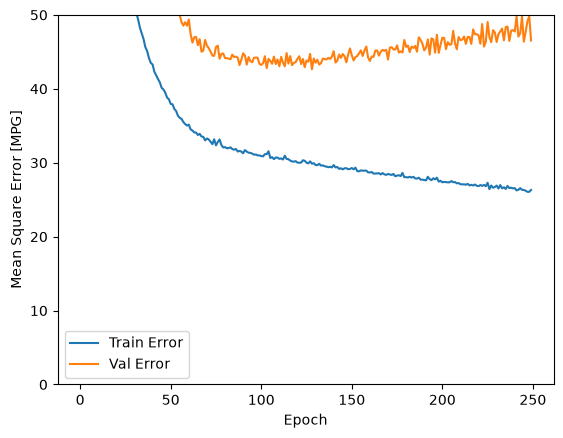

In [12]:
EPOCHS = 250
VERBOSE = 1
BATCH_SIZE = 32

x = torch.as_tensor(normed_train_data, dtype=torch.float32)
y = torch.as_tensor(train_labels.values, dtype=torch.float32).reshape(-1, 1)

split = int(len(x) * (1 - 0.2))
x_train, y_train = x[:split], y[:split]
x_val, y_val = x[split:], y[split:]

history_dict = {"loss": [], "mse": [], "val_loss": [], "val_mse": []}
n = len(x_train)
for epoch in range(EPOCHS):

    model.train()
    perm = torch.randperm(n)
    run_loss = 0.0
    for i in range(0, n, BATCH_SIZE):
        idx = perm[i:i + BATCH_SIZE]
        loss = loss_fn(model(x_train[idx]), y_train[idx])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        run_loss += loss.item() * len(idx)

    # validazione
    model.eval()
    with torch.no_grad():
        val_loss = loss_fn(model(x_val), y_val).item()

    # loss e metrica coincidono perché la loss è già la MSE
    history_dict["loss"].append(run_loss / n)
    history_dict["mse"].append(run_loss / n)
    history_dict["val_loss"].append(val_loss)
    history_dict["val_mse"].append(val_loss)
    if VERBOSE:
        print(f"Epoch {epoch + 1}/{EPOCHS} - loss: {history_dict['loss'][-1]:.4f} - mse: {history_dict['mse'][-1]:.4f}"
              f" - val_loss: {history_dict['val_loss'][-1]:.4f} - val_mse: {history_dict['val_mse'][-1]:.4f}")

e = range(EPOCHS)
plt.figure()
plt.xlabel('Epoch')
plt.ylabel('Mean Square Error [MPG]')
plt.plot(e, history_dict['mse'],label='Train Error')
plt.plot(e, history_dict['val_mse'], label = 'Val Error')
plt.ylim([0,50])
plt.legend()
plt.show()

## EVAL

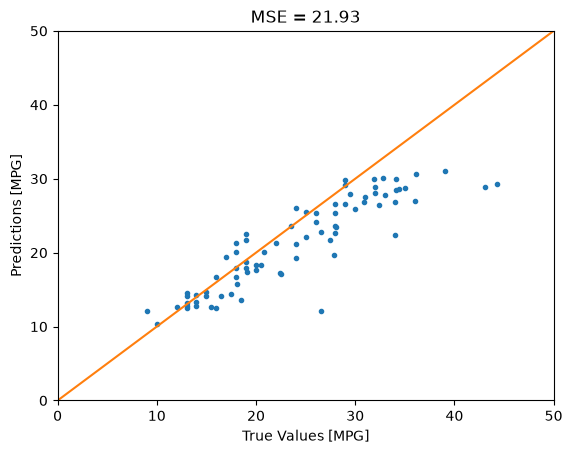

In [10]:
x_test = torch.as_tensor(normed_test_data, dtype=torch.float32)
y_test = torch.as_tensor(test_labels.values, dtype=torch.float32).reshape(-1, 1)

model.eval()
with torch.no_grad():
    test_predictions = model(x_test)
    loss = mse = nn.functional.mse_loss(test_predictions, y_test).item()  # equivalente di model.evaluate
test_predictions = test_predictions.numpy()                # equivalente di model.predict

plt.figure()
#a = plt.axes(aspect='equal')
plt.title(f"MSE = {'%.2f'%(mse)}")
plt.plot(np.array(test_labels), test_predictions,'.')
plt.xlabel('True Values [MPG]')
plt.ylabel('Predictions [MPG]')

lims = [0, 50]
plt.xlim(lims)
plt.ylim(lims)
plt.plot(lims, lims)
plt.show()